# Toxic comments: completed Colab validation and prior evidence

## tl;dr

- The completed **colab-efficient-v1** random-initialized RoBERTa run trained for **five epochs** and selected **epoch 4** by validation loss. On **23,878 validation rows**, macro AP is **0.5259**, macro ROC-AUC **0.9761**, macro F1 **0.5094**, and micro F1 **0.6520** at validation-selected thresholds. These are **selection diagnostics**; its internal test remains unscored.
- The CPU TF-IDF + logistic regression baseline is stronger on the **same verified validation partition**: macro AP **0.6549**, macro F1 **0.6414**, and micro F1 **0.7546** at its own validation-selected thresholds. The completed neural run does not establish a model-quality improvement.
- Historical five-epoch transformer outputs select **epoch 3** by validation loss, with macro ROC-AUC **0.9790** and macro F1 **0.3900** at strict score `> 0.5`. Those historical results use a different split and remain separate below.
- The CPU baseline's previously scored **23,955-row exploratory internal test** has macro AP **0.6502**, macro ROC-AUC **0.9811**, macro F1 **0.6346**, and micro F1 **0.7483**. This is a CPU result; there is no corresponding neural internal-test score.
- The supplied source has **159,571 training-source rows**; the new grouped protocol drops seven normalized-empty texts. The **153,164-row challenge test is unlabeled** and cannot be scored from these files.

This notebook reads committed aggregate evidence only. It does not read raw comments, train a model, download assets, or recreate the historical training.

## Context & Methods

The completed Colab run uses the canonical [notebook 04](04_colab_efficient_training.ipynb): an eight-layer RoBERTa encoder initialized randomly, with the public `roberta-base` tokenizer only. It trains on 111,731 rows, selects the minimum validation-loss checkpoint, reloads that checkpoint for fresh validation, and selects six validation F1 thresholds. Calibration chose microbatch 64 and accumulation 4, preserving nominal effective batch size 256. Resource calibration uses synthetic inputs; it is not an end-to-end speedup or model-quality experiment.

The CPU reference fits TF-IDF and six logistic regressions on training text only. Its validation comparison with the neural run uses the same verified source, labels, and grouped row partition. Each model selects its own thresholds on validation. Only the CPU model has an exploratory internal-test evaluation. Normalized exact-text groups stay in one partition; grouping does not establish independence of paraphrases, authors, discussions, or time.

The original historical notebooks use a different 80/20 random row split and repeatedly inspect validation. Their per-label table uses last-epoch prediction arrays, while demonstration inference reloads a different checkpoint. Those rounded saved outputs are retained as historical evidence.

### Key Assumptions

The cohort was examined historically, so its internal test is not a pristine external benchmark. Later CSV bytes do not prove the identity of the historical training input. Source-level counts precede seven empty-text exclusions; new run supports use retained rows. Unknown challenge-test labels are not negative labels. Undefined metrics remain null. No uncertainty interval, probability-calibration, subgroup, or deployment-readiness evidence is available.

Environment: Python 3.12 and `requirements-notebooks.txt`. From the project root, execute `python scripts/run_results_notebook.py`; its kernel uses the invoking interpreter. The saved notebook's `execution_review` metadata records whether a normal Jupyter kernel or the documented `--engine inprocess` fallback executed it.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

project_root = next(
    candidate for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "reports/historical_metrics.json").is_file()
)
sys.path.insert(0, str(project_root / "scripts"))
from render_historical_results import (
    LABELS, load_evidence, records_by_name, summary_dataframe,
    per_label_dataframe, plot_training_history, plot_per_label_report,
    configure_style, BLUE, ORANGE,
)
from render_real_results import (
    load_data_audit, audit_dataframe, plot_label_prevalence,
    load_run_results, run_summary_dataframe, run_per_label_dataframe,
    plot_run_per_label, tuned_metric_key,
)

from verify_repository import colab_table, validation_comparison_table

from IPython.core.pylabtools import select_figure_formats
select_figure_formats(get_ipython(), {"png"})
historical = load_evidence(project_root / "reports/historical_metrics.json")
data_audit = load_data_audit(project_root / "reports/data_audit.json")
records = records_by_name(historical)
print("Loaded aggregate evidence only; no raw comments or model files.")

Loaded aggregate evidence only; no raw comments or model files.


## Data

### 1. Trace the historical inputs

The committed [historical metrics record](../reports/historical_metrics.json) identifies original file hashes, zero-based cell indexes, output indexes, and execution counts. These are saved outputs, not fresh model measurements. The two five-epoch histories match exactly and are shared evidence rather than independent replications.

In [2]:
source_table = pd.DataFrame([
    {
        "Notebook": name,
        "Recorded epochs": len(record["metrics"]),
        "Metric cell (zero-based)": record["metrics"][0]["cell_index"],
        "Original SHA-256": record["sha256"],
    }
    for name, record in records.items()
])
display(source_table)
selected = records["model_FINAL_Report.ipynb"]["best_by_validation_loss"]
assert selected["epoch"] == 3
assert records["model_FINAL_Report.ipynb"]["per_label_report"]["uses_last_epoch_prediction_arrays_from_cell_6"]

,Notebook,Recorded epochs,Metric cell (zero-based),Original SHA-256
0,Untitled10.ipynb,7,6,a090070703a768766d65ddfef4244da2af1c25fa9fc0f9...
1,modelXXXX(1).ipynb,5,6,6a6377d348a71f03fcecf37b454d7565bddf8d191184b8...
2,model_FINAL_Report.ipynb,5,6,d46c37b06c49d74f2137c23a798128a3cf1f6c21a2b054...


### 2. Inspect the later supplied source cohort

Source: [data audit](../reports/data_audit.json). These six labels overlap. Counts below use all supplied labeled-source rows, before the new run's explicit exclusions.

In [3]:
display(audit_dataframe(data_audit).style.format({"Source prevalence (%)": "{:.3f}"}))
source_checks = pd.DataFrame([
    {"Source finding": "Training-source rows", "Count": data_audit["train"]["rows"]},
    {"Source finding": "Normalized-empty training comments", "Count": data_audit["train"]["normalized_empty_text_rows"]},
    {"Source finding": "Conflicting normalized-text groups", "Count": data_audit["train"]["normalized_conflicting_label_groups"]},
    {"Source finding": "Rows in conflicting groups", "Count": data_audit["train"]["rows_in_conflicting_groups"]},
    {"Source finding": "Unlabeled challenge-test rows", "Count": data_audit["unlabeled_challenge_test"]["rows"]},
    {"Source finding": "Shared nonempty source groups", "Count": data_audit["cross_file_overlap"]["shared_nonempty_normalized_groups"]},
])
display(source_checks)
assert data_audit["unlabeled_challenge_test"]["evaluation_available"] is False
assert all(
    count == data_audit["unlabeled_challenge_test"]["rows"]
    for count in data_audit["unlabeled_challenge_test"]["blank_label_cells"].values()
)

,Label,Positive source rows,Source prevalence (%)
0,identity_hate,1405,0.880
1,insult,7877,4.936
2,obscene,8449,5.295
3,severe_toxic,1595,1.000
4,threat,478,0.300
5,toxic,15294,9.584


,Source finding,Count
0,Training-source rows,159571
1,Normalized-empty training comments,7
2,Conflicting normalized-text groups,93
3,Rows in conflicting groups,213
4,Unlabeled challenge-test rows,153164
5,Shared nonempty source groups,636


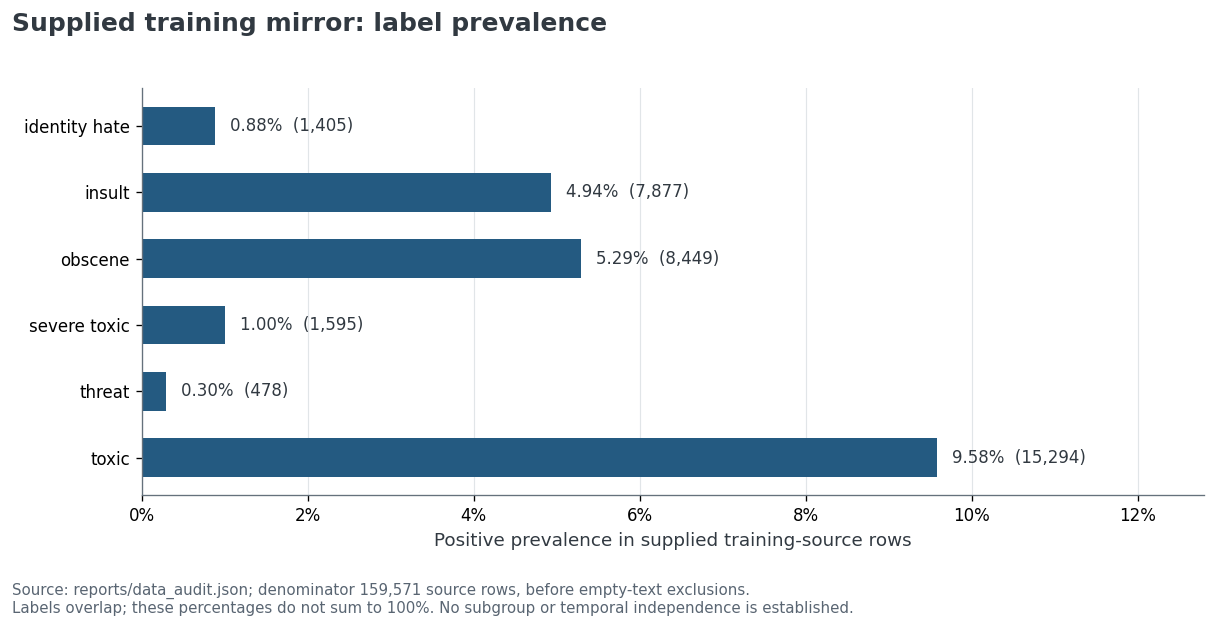

In [4]:
source_figure = plot_label_prevalence(data_audit)
display(source_figure)
plt.close(source_figure)

Threat is present in 478 source rows (about 0.30%), whereas toxic is present in 15,294 (about 9.58%). Class imbalance makes per-label supports and precision essential. The challenge-test file has blank target columns, so no score can be computed from it. Separate filenames and IDs do not undo the 636 shared normalized-text groups.

## Results

The completed neural run and its same-validation CPU comparison are presented first. Historical neural outputs and the CPU-only exploratory internal test remain separate sections.

### 3. Review the completed canonical Colab run

Source: [reports/colab_efficient_v1](../reports/colab_efficient_v1). The returned review bundle, private verification arrays, exact source/split fingerprints, threshold selection, and saved calibration were checked before publication. This notebook rechecks the published table contracts and derives editable plots from the public aggregates. It does not access the private verification files.

The public [verification summary](../reports/colab_efficient_v1/verification.json) records the evidence checks. Raw text, row arrays, model weights, and private identifiers are excluded. Validation losses and scores describe the reloaded **loss-best checkpoint**, not the final epoch.

In [5]:
colab_directory = project_root / "reports/colab_efficient_v1"
def read_colab_json(filename):
    return json.loads((colab_directory / filename).read_text(encoding="utf-8"))

neural_results = read_colab_json("validation_metrics.json")
neural_config = read_colab_json("config.json")
neural_history = read_colab_json("training_history.json")
neural_metadata = read_colab_json("result_metadata.json")
neural_runtime = read_colab_json("run_metadata.json")
calibration = read_colab_json("calibration.json")
verification = read_colab_json("verification.json")
assert verification["status"] == "verified_returned_validation_artifacts"
assert verification["baseline_same_validation_comparison_verified"] is True

assert neural_metadata["stage"] == "developed_and_frozen"
assert neural_metadata["test_evaluation_performed"] is False
assert neural_metadata["validation_is_selection_diagnostic"] is True
selected_neural = min(neural_history["epochs"], key=lambda row: row["validation_loss"])
assert selected_neural["epoch"] == neural_history["best_checkpoint"]["epoch"]
assert np.isclose(neural_history["fresh_validation_loss"], selected_neural["validation_loss"], atol=1e-12, rtol=0)
assert neural_config["training"]["batch_size"] == calibration["batch_size"]
assert neural_config["training"]["accumulation_steps"] == calibration["accumulation_steps"]

display(pd.DataFrame([
    {"Recorded property": "Completed / selected epoch", "Value": f"{len(neural_history['epochs'])} / {selected_neural['epoch']}"},
    {"Recorded property": "Fresh selected-checkpoint validation BCE", "Value": f"{neural_history['fresh_validation_loss']:.6f}"},
    {"Recorded property": "Microbatch × accumulation", "Value": f"{neural_config['training']['batch_size']} × {neural_config['training']['accumulation_steps']}"},
    {"Recorded property": "Model initialization", "Value": neural_runtime["initialization"]},
    {"Recorded property": "Internal test", "Value": "Not evaluated"},
    {"Recorded property": "Source SHA-256", "Value": neural_metadata["source_sha256"]},
]))
display(Markdown(colab_table(project_root)))


,Recorded property,Value
0,Completed / selected epoch,5 / 4
1,Fresh selected-checkpoint validation BCE,0.360142
2,Microbatch × accumulation,64 × 4
3,Model initialization,random weights; no pretrained model weights
4,Internal test,Not evaluated
5,Source SHA-256,bb7a9e1af5282c4c05bf09bf3be3373c4160fe3272a4b2...


| Partition | Threshold policy | Rows | Macro AP | Macro ROC-AUC | Macro F1 | Micro F1 |
|---|---|---:|---:|---:|---:|---:|
| Validation | Fixed 0.5 | 23878 | 0.5259 | 0.9761 | 0.3928 | 0.4943 |
| Validation | Validation-selected | 23878 | 0.5259 | 0.9761 | 0.5094 | 0.6520 |

#### Loss history and checkpoint selection

The minimum validation BCE is **0.360142 at epoch 4**; the final epoch's validation BCE is **0.393619**. Fresh validation of the reloaded selected export matches epoch 4. The chart shows sample-weighted losses from the returned run, not the differently aggregated historical notebook losses.

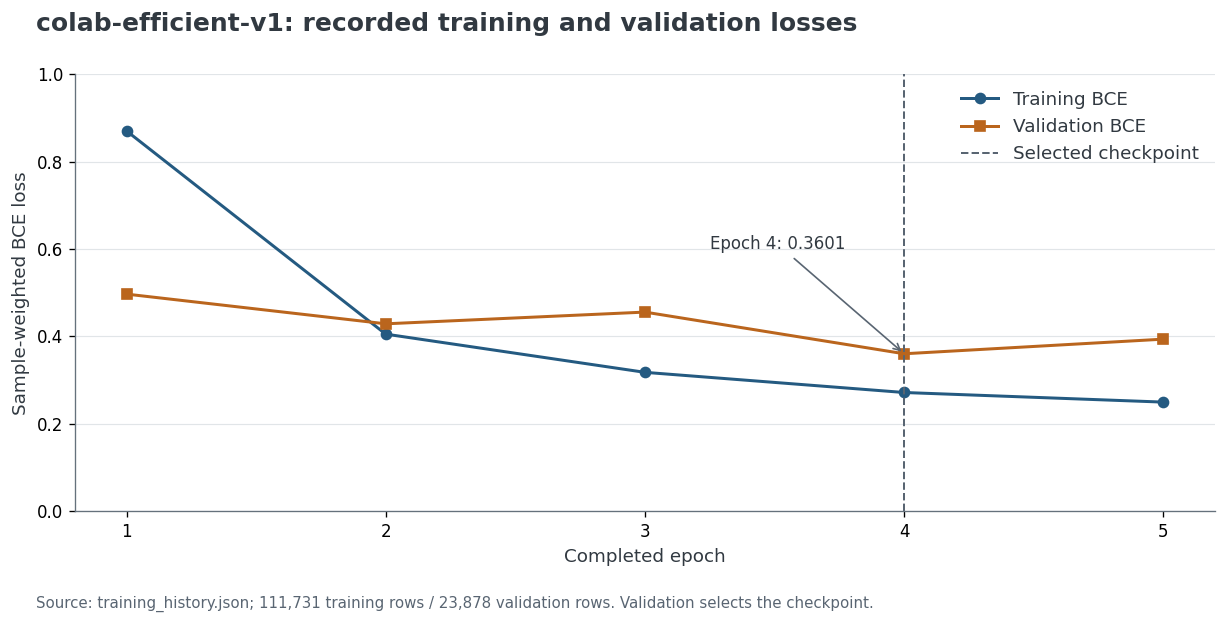

In [6]:
configure_style()
neural_epoch_table = pd.DataFrame(neural_history["epochs"])
figure, axis = plt.subplots(figsize=(10.8, 5.2))
axis.plot(neural_epoch_table["epoch"], neural_epoch_table["training_loss"], color=BLUE, marker="o", label="Training BCE")
axis.plot(neural_epoch_table["epoch"], neural_epoch_table["validation_loss"], color=ORANGE, marker="s", label="Validation BCE")
axis.axvline(selected_neural["epoch"], color="#596572", linestyle="--", linewidth=1.2, label="Selected checkpoint")
axis.annotate(f"Epoch {selected_neural['epoch']}: {selected_neural['validation_loss']:.4f}",
              xy=(selected_neural["epoch"], selected_neural["validation_loss"]),
              xytext=(3.25, 0.60), arrowprops={"arrowstyle": "->", "color": "#596572"}, fontsize=10)
axis.set(xlabel="Completed epoch", ylabel="Sample-weighted BCE loss", xticks=neural_epoch_table["epoch"], ylim=(0, 1.0))
axis.grid(axis="y")
axis.legend(loc="upper right", frameon=False)
figure.suptitle("colab-efficient-v1: recorded training and validation losses", x=0.06, ha="left", fontsize=15, fontweight="bold")
figure.text(0.06, 0.025, "Source: training_history.json; 111,731 training rows / 23,878 validation rows. Validation selects the checkpoint.", fontsize=9, color="#596572")
figure.subplots_adjust(left=0.09, right=0.97, bottom=0.18, top=0.88)
display(figure)
plt.close(figure)


#### Resource calibration is separate from quality evidence

The saved synthetic, full-length resource probes selected batch 64 × accumulation 4. Each candidate used one warmup group and two measured groups. These are short resource probes on the recorded Tesla T4, not measurements of total training time or a speedup over the legacy notebook. Dynamic padding, preprocessing, checkpoint I/O, and real sequence lengths can change throughput.

In [7]:
calibration_rows = pd.DataFrame([
    {"Microbatch": row["batch_size"], "Accumulation": row["accumulation_steps"],
     "Synthetic samples / second": row["samples_per_second"],
     "Peak reserved GPU GiB": row["peak_reserved_gpu_bytes"] / 2**30,
     "Within memory budget": row["within_memory_budget"]}
    for row in calibration["records"] if row["status"] == "ok"
])
display(calibration_rows.style.format({"Synthetic samples / second": "{:.1f}", "Peak reserved GPU GiB": "{:.2f}"}))


,Microbatch,Accumulation,Synthetic samples / second,Peak reserved GPU GiB,Within memory budget
0,8,32,63.8,1.55,True
1,16,16,123.3,2.11,True
2,32,8,181.8,3.33,True
3,64,4,187.9,5.74,True


### 4. Compare models on the same validation partition

Source: [baseline_validation_comparison.json](../reports/colab_efficient_v1/baseline_validation_comparison.json). Source bytes, grouped split indices, label order, validation labels, and supports match. Both models use 23,878 validation rows and `score >= threshold`; each selects its own thresholds on these rows. The table includes both fixed 0.5 and validation-selected policies.

The CPU baseline is higher on validation macro AP and F1. These observed differences describe this selection partition; no uncertainty interval or independent generalization advantage is established. Historical neural scores and CPU internal-test scores are excluded from this comparison.

In [8]:
comparison = read_colab_json("baseline_validation_comparison.json")
assert comparison["same_source_same_split_verified"] is True
assert comparison["split"] == "validation"
display(Markdown(validation_comparison_table(project_root)))
compared_models = comparison["models"]
compared_metric_keys = ("macro_average_precision", "macro_f1", "micro_f1")
comparison_deltas = {
    key: compared_models["neural"]["metrics_at_validation_thresholds"][key]
         - compared_models["baseline"]["metrics_at_validation_thresholds"][key]
    for key in compared_metric_keys
}
display(Markdown(
    "Neural minus CPU baseline on this validation partition: "
    + "; ".join(f"**{name}: {comparison_deltas[key]:+.4f}**" for name, key in
                zip(("macro AP", "macro F1", "micro F1"), compared_metric_keys)) + "."
))


| Model | Threshold policy | Validation rows | Macro AP | Macro ROC-AUC | Macro F1 | Micro F1 |
|---|---|---:|---:|---:|---:|---:|
| TF-IDF + logistic regression | Fixed 0.5 | 23878 | 0.6549 | 0.9823 | 0.6087 | 0.7257 |
| TF-IDF + logistic regression | Validation-selected | 23878 | 0.6549 | 0.9823 | 0.6414 | 0.7546 |
| Random RoBERTa | Fixed 0.5 | 23878 | 0.5259 | 0.9761 | 0.3928 | 0.4943 |
| Random RoBERTa | Validation-selected | 23878 | 0.5259 | 0.9761 | 0.5094 | 0.6520 |

Neural minus CPU baseline on this validation partition: **macro AP: -0.1290**; **macro F1: -0.1320**; **micro F1: -0.1026**.

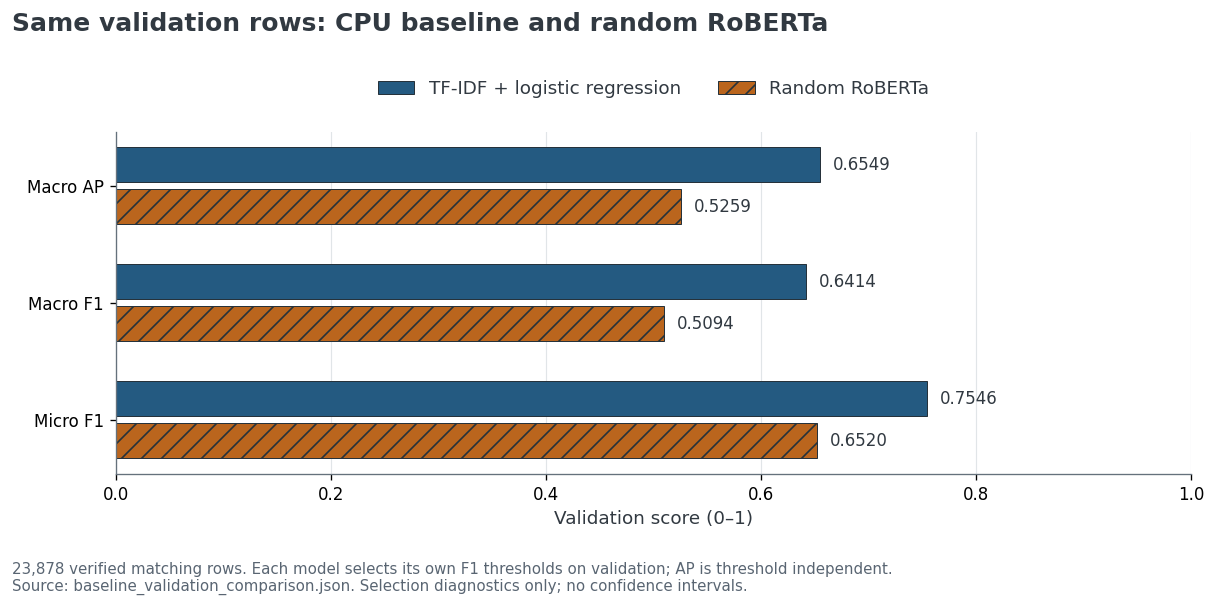

In [9]:
configure_style()
positions = np.arange(len(compared_metric_keys))
figure, axis = plt.subplots(figsize=(10.8, 5.0))
for model_key, title, color, offset, hatch in (
    ("baseline", "TF-IDF + logistic regression", BLUE, -0.18, ""),
    ("neural", "Random RoBERTa", ORANGE, 0.18, "//"),
):
    values = [compared_models[model_key]["metrics_at_validation_thresholds"][key] for key in compared_metric_keys]
    axis.barh(positions + offset, values, height=0.30, color=color, hatch=hatch,
              label=title, edgecolor="#26323B", linewidth=0.6)
    for position, value in zip(positions + offset, values):
        axis.text(value + 0.012, position, f"{value:.4f}", va="center", fontsize=10)
axis.set(yticks=positions, yticklabels=("Macro AP", "Macro F1", "Micro F1"),
         xlim=(0, 1), xlabel="Validation score (0–1)")
axis.invert_yaxis()
axis.grid(axis="x")
axis.set_axisbelow(True)
axis.legend(loc="upper center", bbox_to_anchor=(0.5, 1.20), ncol=2, frameon=False)
figure.suptitle("Same validation rows: CPU baseline and random RoBERTa", x=0.06, y=0.99, ha="left", fontsize=15, fontweight="bold")
figure.text(0.06, 0.025, "23,878 verified matching rows. Each model selects its own F1 thresholds on validation; AP is threshold independent.\nSource: baseline_validation_comparison.json. Selection diagnostics only; no confidence intervals.", fontsize=9, color="#596572")
figure.subplots_adjust(left=0.14, right=0.97, bottom=0.22, top=0.79)
display(figure)
plt.close(figure)


### 5. Inspect neural validation labels and operating points

Source: [validation_metrics.json](../reports/colab_efficient_v1/validation_metrics.json) and [thresholds.json](../reports/colab_efficient_v1/thresholds.json). All six labels have ranking and F1 coverage. Supports reconcile to 23,878 validation rows. Five selected thresholds are at the search grid's upper boundary, 0.95; toxic uses 0.90. These selected values do not establish probability calibration.

Threat has only **62 positive validation rows**, AP **0.0753**, and selected-threshold precision **0.0590**. The selected-threshold F1 rises from **0.0682** to **0.1081**, while many false positives remain. Read precision, recall, and support alongside ranking scores.

In [10]:
neural_label_table = run_per_label_dataframe(neural_results)
display(neural_label_table.style.format({
    "Threshold": "{:.2f}", "AP": "{:.4f}", "ROC-AUC": "{:.4f}",
    "Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}",
}, na_rep="undefined"))


,Label,Positive support,Threshold,AP,ROC-AUC,Precision,Recall,F1
0,identity_hate,209,0.95,0.1830,0.9696,0.1513,0.6603,0.2462
1,insult,1179,0.95,0.7162,0.9788,0.6380,0.7625,0.6947
2,obscene,1273,0.95,0.8573,0.9891,0.7325,0.8303,0.7784
3,severe_toxic,237,0.95,0.4688,0.9890,0.3126,0.8481,0.4568
4,threat,62,0.95,0.0753,0.9589,0.0590,0.6452,0.1081
5,toxic,2315,0.90,0.8549,0.9711,0.7489,0.7974,0.7724


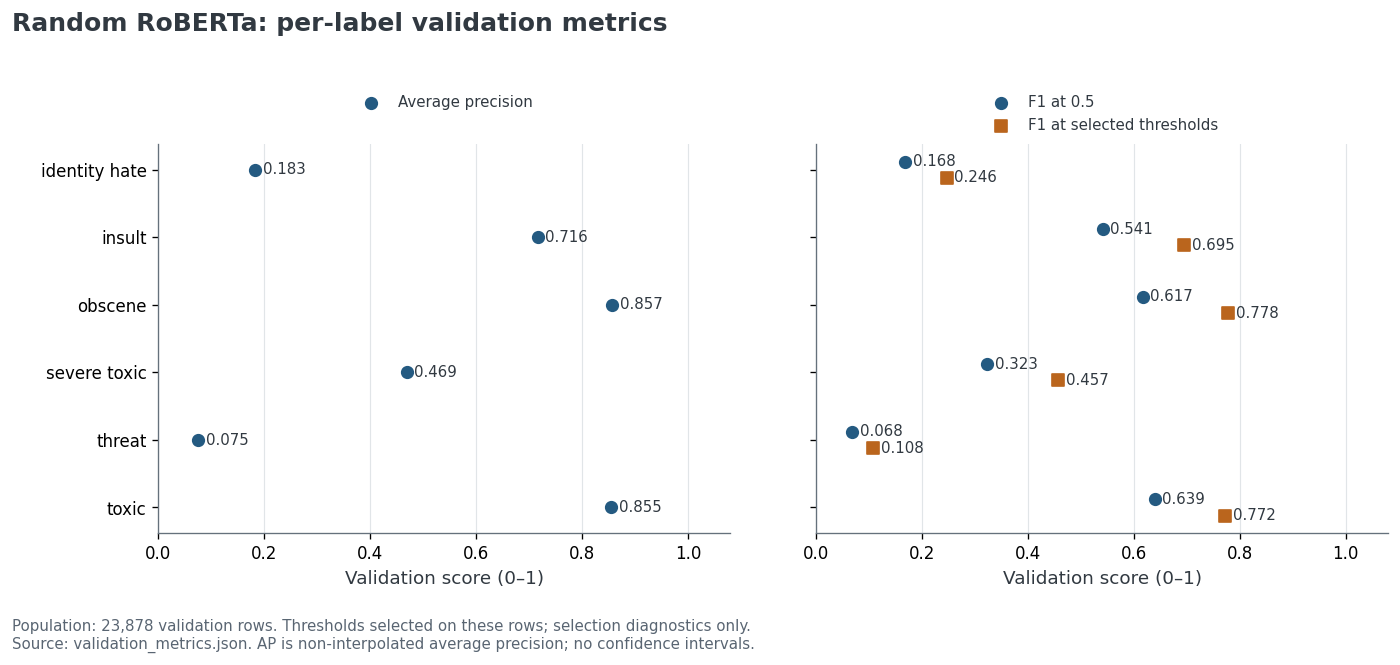

In [11]:
configure_style()
fixed_neural = neural_results["metrics_at_0_5"]
tuned_neural = neural_results["metrics_at_validation_thresholds"]
figure, axes = plt.subplots(1, 2, figsize=(12.2, 5.5), sharey=True)
positions = np.arange(len(LABELS))
for axis, series in zip(axes, (
    (("Average precision", "average_precision", tuned_neural, BLUE, "o", 0),),
    (("F1 at 0.5", "f1", fixed_neural, BLUE, "o", -0.12),
     ("F1 at selected thresholds", "f1", tuned_neural, ORANGE, "s", 0.12)),
)):
    for title, field, metric_set, color, marker, offset in series:
        values = [metric_set["per_label"][label][field] for label in LABELS]
        axis.scatter([np.nan if value is None else value for value in values], positions + offset,
                     color=color, marker=marker, s=48, label=title, zorder=3)
        for position, value in zip(positions + offset, values):
            if value is not None:
                axis.text(value + 0.014, position, f"{value:.3f}", va="center", fontsize=9)
    axis.set(yticks=positions, yticklabels=[label.replace("_", " ") for label in LABELS],
             xlim=(0, 1.08), xlabel="Validation score (0–1)")
    axis.grid(axis="x")
    axis.legend(loc="upper center", bbox_to_anchor=(0.5, 1.16), frameon=False, fontsize=9)
axes[0].invert_yaxis()
figure.suptitle("Random RoBERTa: per-label validation metrics", x=0.04, y=0.99, ha="left", fontsize=15, fontweight="bold")
figure.text(0.04, 0.025, "Population: 23,878 validation rows. Thresholds selected on these rows; selection diagnostics only.\nSource: validation_metrics.json. AP is non-interpolated average precision; no confidence intervals.", fontsize=9, color="#596572")
figure.subplots_adjust(left=0.14, right=0.98, bottom=0.20, top=0.79, wspace=0.15)
display(figure)
plt.close(figure)


### 6. Separate selected and final historical checkpoints

The following sections preserve the original saved outputs from a different split protocol. Their F1 uses strict `score > 0.5`, and table precision reflects the original four-decimal logs. Every historical row describes repeatedly inspected validation data; it is not the completed colab-efficient-v1 run.

In [12]:
historical_summary = summary_dataframe(historical)
display(historical_summary.style.format({
    "Validation loss": "{:.4f}", "Macro ROC-AUC": "{:.4f}", "Macro F1 at > 0.5": "{:.4f}",
}))

,Notebook,Recorded checkpoint,Epoch,Validation loss,Macro ROC-AUC,Macro F1 at > 0.5
0,model_FINAL_Report.ipynb,Selected by validation loss,3,0.3482,0.9790,0.3900
1,model_FINAL_Report.ipynb,Last epoch,5,0.3824,0.9792,0.4391
2,Untitled10.ipynb,Selected by validation loss,4,0.3498,0.9801,0.3818
3,Untitled10.ipynb,Last epoch,7,0.4081,0.9810,0.4459
4,modelXXXX(1).ipynb,Selected by validation loss,3,0.3482,0.9790,0.3900
5,modelXXXX(1).ipynb,Last epoch,5,0.3824,0.9792,0.4391


### 7. Review stored loss trajectories

The panels share a loss scale. Vertical guides identify selection by minimum validation loss. `modelXXXX(1).ipynb` is omitted from this plot because its stored five-epoch history is identical to FINAL_Report.

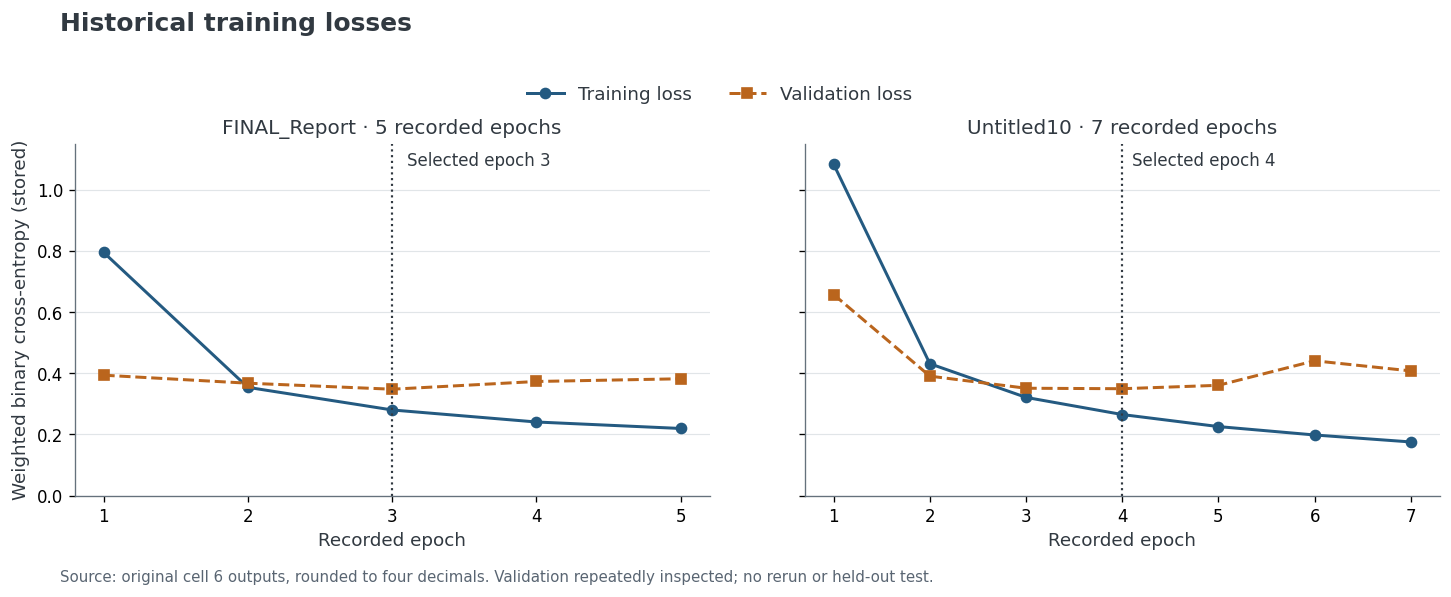

In [13]:
loss_figure = plot_training_history(historical)
display(loss_figure)
plt.close(loss_figure)

The five-epoch minimum validation loss is 0.3482 at epoch 3; its last-epoch loss is 0.3824. Untitled10 selects epoch 4 and records three subsequent non-improving losses. Different learning rate, warmup, and duration prevent attributing differences to one change. The original loss aggregation is also a mean of batch means, so these stored losses retain that historical limitation.

### 8. Review the historical operating point

The per-label output comes from FINAL_Report cell 9, whose execution count is null. Its source uses final-epoch arrays. The stored macro row is preserved rather than recalculated from rounded label values. No support counts, confidence intervals, or calibration evidence accompany this historical table.

In [14]:
display(per_label_dataframe(historical).style.format({"Precision": "{:.3f}", "Recall": "{:.3f}", "F1": "{:.3f}"}))

,Label,Precision,Recall,F1
0,identity_hate,0.124,0.911,0.218
1,insult,0.440,0.945,0.601
2,obscene,0.539,0.959,0.690
3,severe_toxic,0.203,0.975,0.336
4,threat,0.048,0.853,0.090
5,toxic,0.572,0.900,0.700
6,Macro mean (stored),0.321,0.924,0.439


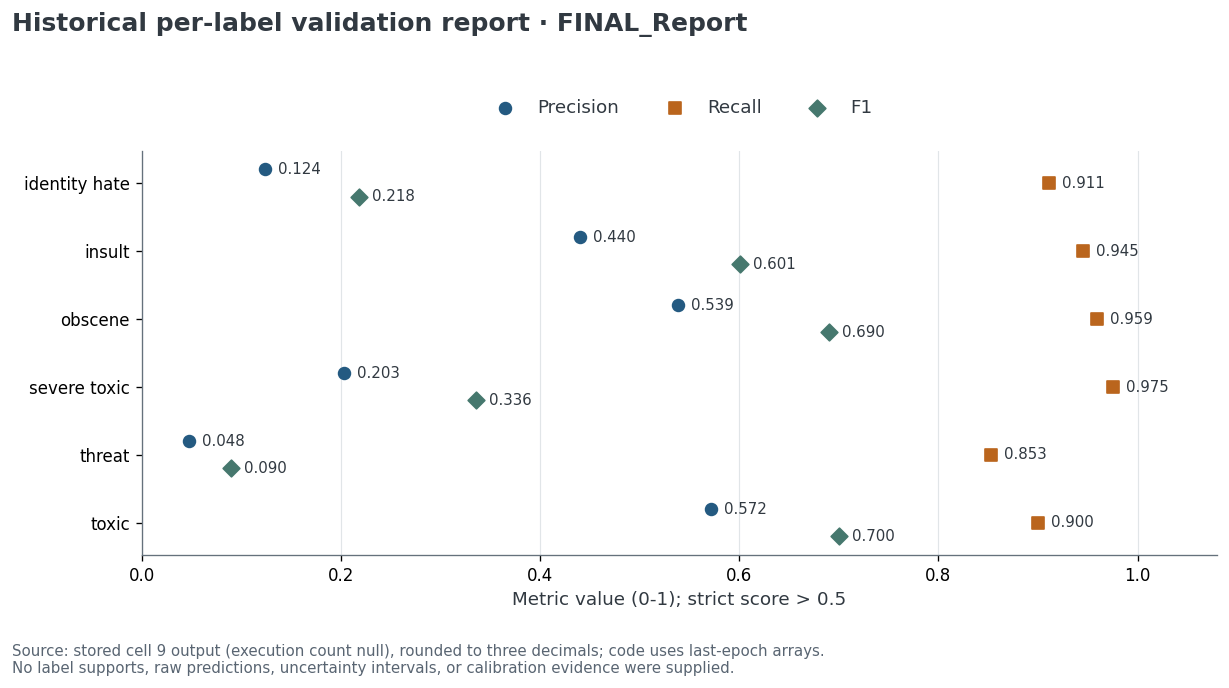

In [15]:
operating_point_figure = plot_per_label_report(historical)
display(operating_point_figure)
plt.close(operating_point_figure)

The stored macro precision is 0.321 and macro recall is 0.924. Threat and identity hate have high recall but low precision. ROC-AUC measures ranking across thresholds; it does not imply accuracy or low false-positive rates at 0.5. Macro F1 is the mean of per-label F1, not the harmonic mean of macro precision and macro recall.

### 9. Review the CPU baseline and its exploratory internal test separately

Inputs: `reports/baseline_validation_metrics.json` and `reports/baseline_internal_test_metrics.json`. These results are from the completed real-data CPU run; its internal-test scores do not belong to the neural model. The cohort, partitions, model family, and threshold rule differ from the historical transformer experiment. New binary decisions use `score >= threshold`. Validation metrics are selection diagnostics. Internal-test metrics remain exploratory because this cohort was examined previously.

The primary new metric is six-label macro average precision (AP), calculated using scikit-learn's non-interpolated average precision, not trapezoidal PR area. Ranking coverage must be 6/6 to interpret the full six-label macro. The reviewed policies explicitly drop seven empty-text rows and retain conflicting annotations without label merging.

In [16]:
cpu_results = {}
for partition, filename in (
    ("Validation (selection diagnostics)", "baseline_validation_metrics.json"),
    ("Exploratory internal test", "baseline_internal_test_metrics.json"),
):
    source_path = project_root / "reports" / filename
    cpu_results[partition] = load_run_results(source_path)
    display(Markdown(f"**CPU {partition}** — source: `{filename}`"))
    display(run_summary_dataframe(cpu_results[partition]).style.format({
        "Macro AP": "{:.4f}", "Macro ROC-AUC": "{:.4f}", "Macro F1": "{:.4f}", "Micro F1": "{:.4f}",
    }, na_rep="undefined"))

**CPU Validation (selection diagnostics)** — source: `baseline_validation_metrics.json`

,Threshold policy,Rows,Macro AP,Macro ROC-AUC,Macro F1,Micro F1,Ranking labels
0,Fixed 0.5,23878,0.6549,0.9823,0.6087,0.7257,6/6
1,Validation-selected,23878,0.6549,0.9823,0.6414,0.7546,6/6


**CPU Exploratory internal test** — source: `baseline_internal_test_metrics.json`

,Threshold policy,Rows,Macro AP,Macro ROC-AUC,Macro F1,Micro F1,Ranking labels
0,Fixed 0.5,23955,0.6502,0.9811,0.6144,0.7330,6/6
1,Validation-selected,23955,0.6502,0.9811,0.6346,0.7483,6/6


### 10. Inspect CPU-only internal-test label supports and metrics

Null values retain their undefined meaning. Selected thresholds come only from validation and are frozen before this evaluation. The table and chart are aggregate-only and do not reveal comments or individual decisions.

In [17]:
internal_results = cpu_results.get("Exploratory internal test")
if internal_results is not None:
    display(run_per_label_dataframe(internal_results).style.format({
        "Threshold": "{:.2f}", "AP": "{:.4f}", "ROC-AUC": "{:.4f}",
        "Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}",
    }, na_rep="undefined"))
else:
    display(Markdown("No committed internal-test aggregate is available to review yet."))

,Label,Positive support,Threshold,AP,ROC-AUC,Precision,Recall,F1
0,identity_hate,224,0.70,0.4887,0.9704,0.4206,0.6027,0.4954
1,insult,1196,0.60,0.7868,0.9791,0.6655,0.8002,0.7267
2,obscene,1290,0.70,0.8928,0.9879,0.8241,0.8209,0.8225
3,severe_toxic,261,0.80,0.4611,0.9875,0.4329,0.6054,0.5048
4,threat,67,0.85,0.3884,0.9856,0.4400,0.4925,0.4648
5,toxic,2299,0.75,0.8833,0.9763,0.8383,0.7529,0.7933


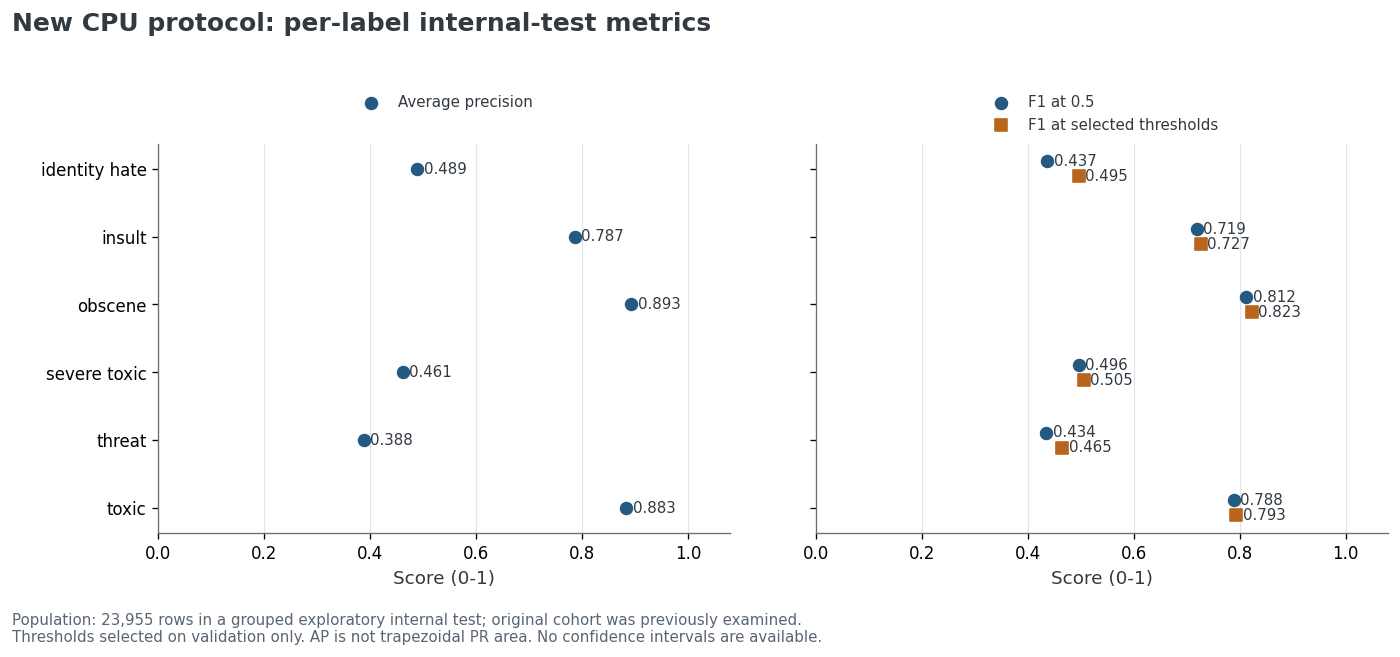

The new CPU protocol scores **23,955 internal-test rows**, with ranking coverage **6/6**. The threshold comparison reuses this model's scores; it is not a neural-versus-baseline comparison. No confidence interval or untouched external cohort is supplied.

In [18]:
if internal_results is not None:
    internal_figure = plot_run_per_label(internal_results)
    display(internal_figure)
    plt.close(internal_figure)
    metrics = internal_results[tuned_metric_key(internal_results)]
    display(Markdown(
        f"The new CPU protocol scores **{metrics['rows']:,} internal-test rows**, "
        f"with ranking coverage **{metrics['coverage']['ranking_eligible_count']}/6**. "
        "The threshold comparison reuses this model's scores; it is not a neural-versus-baseline comparison. "
        "No confidence interval or untouched external cohort is supplied."
    ))

## Takeaways

1. The completed efficient Colab run is reproducible aggregate validation evidence, with loss-best epoch 4 and a frozen threshold policy. Its internal test has not been evaluated.
2. The CPU baseline has higher macro AP and F1 on the same validation rows. This result does not establish a neural quality improvement; the short synthetic calibration also does not establish an end-to-end training speedup.
3. Treat validation-selected thresholds as selection diagnostics. Threat remains weak in the neural run: validation AP **0.0753** and selected-threshold precision **0.0590**. High ROC-AUC does not establish moderation utility or calibrated probabilities.
4. Keep historical neural outputs, the completed new neural validation run, source findings, synthetic mechanics/calibration, and CPU internal-test scores distinct. Historical and new split protocols do not support a controlled before/after quality comparison.
5. Stronger generalization claims need an independently collected cohort and a fixed evaluation plan. No pristine external test, uncertainty interval, subgroup audit, latency measurement, or deployment-readiness assessment is established.

[Methodology](../docs/methodology.md), [model card](../docs/model_card.md), [corrected report](../reports/corrected_report.md), [source provenance](../docs/provenance.md), and [claim corrections](../docs/report_corrections.md) provide the audit context.